# testing and clustering
## setup

In [1]:
import pandas as pd
from collections import Counter
import os
import torch
from tqdm.notebook import tqdm
from transformers import (
     pipeline,
)
import spacy
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay
import plotly.express as px
import plotly.io as pio

In [2]:
## global variables and setup
MODEL = "../../projects/classifier/spatial-entities-classifier/models/modern-gbert-binary-nnse-best/"
CORPUS_PATH = "../corpora-collection/sunset-corpus/src/normalized/"
pio.templates.default="gridon"

In [3]:
## spacy
nlp = spacy.load("de_dep_news_trf", 
                 exclude=[
        "tagger",
        "morphologizer",
        "lemmatizer",
        "attribute_ruler",
    ],)

In [4]:
## load trained model
classifier = pipeline(
    task="token-classification",
    model=MODEL,
    tokenizer=MODEL,
    aggregation_strategy="none",
    device=0 if torch.cuda.is_available() else -1,
)

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

In [5]:
# helper functions
def split_into_chunks(text: str, chunk_size: int = 300) -> list[str]:
    words = text.split()

    return [
        " ".join(words[i:i + chunk_size])
        for i in range(0, len(words), chunk_size)
    ]

In [6]:
def join_subwords(tokens: list[str]) -> list[str]:
    result = []

    for token in tokens:
        if token.startswith("##") and result:
            result[-1] += token[2:]
        else:
            result.append(token)

    return result

In [7]:
def create_nnse_counter_matrix(n_chunks=25):
    counter = WordCountMatrix()
    
    for file in tqdm(list(df.filename)):
        with open(CORPUS_PATH + file) as f:
            text = f.read()
        #chunk text
        chunks = split_into_chunks(text=text, chunk_size=300)
        # only look at beginning of text
        max_chunk_size = n_chunks
        if len(chunks)>max_chunk_size:
            chunks_to_process = chunks[:max_chunk_size]
        else:
            chunks_to_process = chunks
        # create sentences
        docs = nlp.pipe(chunks_to_process, batch_size=32, n_process=1)
        sentences = [
            sent.text
            for doc in docs
            for sent in doc.sents
        ]
        # extract nnse
        predictions = classifier(sentences)
        words_raw = [
            prediction["word"]
            for document_predictions in predictions
            for prediction in document_predictions
        ]
        words = join_subwords(words_raw)
        # update WordCountMatrix
        counter.update(words, column_name=file)
    return counter

In [8]:
# custom counter class
from collections import Counter

import pandas as pd


class WordCountMatrix:
    def __init__(self):
        self.vocabulary: list[str] = []
        self._known_words: set[str] = set()
        self.documents: list[Counter] = []
        self.column_names: list[str] = []

    def update(
        self,
        words: list[str],
        column_name: str,
    ) -> None:
        """Add one word list as a named matrix column."""
        if column_name in self.column_names:
            raise ValueError(
                f"Column name already exists: {column_name}"
            )

        self.documents.append(Counter(words))
        self.column_names.append(column_name)

        for word in words:
            if word not in self._known_words:
                self._known_words.add(word)
                self.vocabulary.append(word)

    def update_many(
        self,
        word_lists: list[list[str]],
        column_names: list[str],
    ) -> None:
        """Add several named word lists."""
        if len(word_lists) != len(column_names):
            raise ValueError(
                "word_lists and column_names must have the same length."
            )

        for words, column_name in zip(word_lists, column_names):
            self.update(words, column_name)

    def to_dataframe(self) -> pd.DataFrame:
        """Return words as rows and word lists as columns."""
        data = {
            column_name: [
                document.get(word, 0)
                for word in self.vocabulary
            ]
            for column_name, document in zip(
                self.column_names,
                self.documents,
            )
        }

        return pd.DataFrame(
            data,
            index=self.vocabulary,
            dtype=float,
        )

    @staticmethod
    def _z_transform(
        df: pd.DataFrame,
        axis: int = 0,
    ) -> pd.DataFrame:
        """
        Apply a z-transformation.

        axis=0:
            Standardize each document column across words.

        axis=1:
            Standardize each word across documents.
        """
        if axis == 0:
            means = df.mean(axis=0)
            stds = df.std(axis=0, ddof=0).replace(0, 1)

            return (df - means) / stds

        if axis == 1:
            means = df.mean(axis=1)
            stds = df.std(axis=1, ddof=0).replace(0, 1)

            return df.sub(means, axis=0).div(stds, axis=0)

        raise ValueError("axis must be 0 or 1.")

    def to_z_dataframe(
        self,
        axis: int = 0,
    ) -> pd.DataFrame:
        """Return the complete z-transformed matrix."""
        df = self.to_dataframe()
        return self._z_transform(df, axis=axis)

    def most_frequent(
        self,
        n: int,
        z_transform: bool = False,
        axis: int = 0,
    ) -> pd.DataFrame:
        """
        Return the n most frequent words.

        Frequencies are calculated from the raw count matrix.
        The selected rows can optionally be z-transformed.
        """
        if n < 1:
            raise ValueError("n must be at least 1.")

        df = self.to_dataframe()

        # Select words using their raw total frequency.
        total_counts = df.sum(axis=1)
        selected_words = total_counts.nlargest(n).index

        result = df.loc[selected_words].copy()

        if z_transform:
            result = self._z_transform(
                result,
                axis=axis,
            )

        return result

    def to_numpy(self):
        """Return the complete count matrix as a NumPy array."""
        return self.to_dataframe().to_numpy()

## eval-loop

In [9]:
df = pd.read_csv("src/city_country_metadata.tsv", sep="\t")
len(df)

156

In [10]:
df.label.value_counts()

label
1    61
0    56
2    39
Name: count, dtype: int64

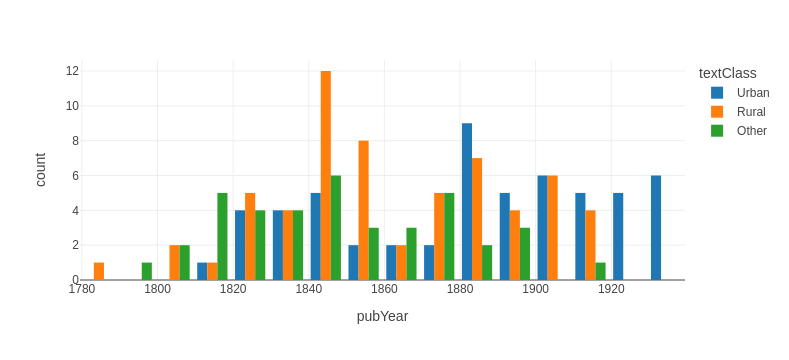

In [11]:
px.histogram(df, x="pubYear", color="textClass", barmode='group')

In [12]:
# single configuration - testing
y_true = df["label"]
n_labels=len(df.label.unique())
n_chunks=50

f1_old=0

counter = create_nnse_counter_matrix(n_chunks=n_chunks)

  0%|          | 0/156 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

In [16]:
f1_old=0
for mf_nnse in range(500, 4100, 100):
    # mfnnse
    matrix = counter.most_frequent(
            n=mf_nnse,
            z_transform=True,
            axis=0,
            )
        
    document_clusters = pd.Series(
                KMeans(
                    n_clusters=n_labels,
                    random_state=42,
                    n_init="auto",
                ).fit_predict(matrix.T),
                index=matrix.columns,
                name="cluster",
            )
    
    precision, recall, f1, support = precision_recall_fscore_support(y_true=y_true, y_pred=list(document_clusters), average='macro')
        
    row = f"mf-nnse: {mf_nnse}\tprec: {precision}\trecall: {recall}\tF1: {f1}"
    print(row)
    
    if f1_old < f1:
        best_mfnnse = mf_nnse
    if f1_old >= f1:
        continue

mf-nnse: 500	prec: 0.10551854319342661	recall: 0.09267849636702097	F1: 0.09445456298613641
mf-nnse: 600	prec: 0.09720545277507303	recall: 0.09267849636702097	F1: 0.09262566137566138
mf-nnse: 700	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 800	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 900	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 1000	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 1100	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 1200	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 1300	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.07994140736727155
mf-nnse: 1400	prec: 0.0917948717948718	recall: 0.08721401549270402	F1: 0.08468721311645343
mf-nnse: 1500	prec: 0.08760683760683761	recall: 0.08174953461838708	F1: 0.079941407367

4000


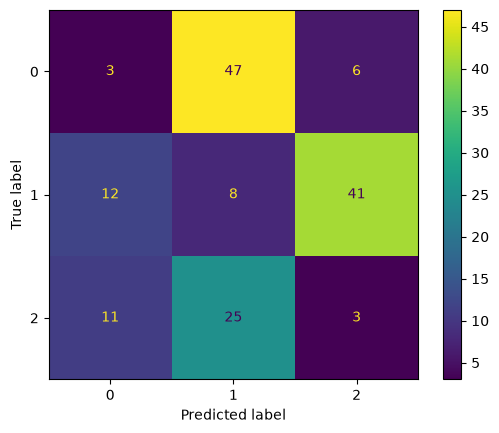

In [17]:
print(best_mfnnse)
matrix = counter.most_frequent(
            n=best_mfnnse,
            z_transform=True,
            axis=0,
            )

document_clusters = pd.Series(
                KMeans(
                    n_clusters=n_labels,
                    random_state=42,
                    n_init="auto",
                ).fit_predict(matrix.T),
                index=matrix.columns,
                name="cluster",
            )

cm = confusion_matrix(y_true=df["label"], y_pred=list(document_clusters))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

In [22]:
# chunks and mf-nnse testing

y_true = df["label"]
n_labels=len(df.label.unique())

filename = "eval-kmean.tsv"

header="chunks\tmf_nnse\tprecision\trecall\tf1\tlist_predictions\n"
with open(filename, "w") as f:
    f.write(header)

for n_chunks in range(100, 700, 100):
    counter = create_nnse_counter_matrix(n_chunks=n_chunks)
    for mf_nnse in range(50, 10050, 50):
        # mfnnse
        matrix = counter.most_frequent(
            n=mf_nnse,
            z_transform=True,
            axis=0,
            )
        
        document_clusters = pd.Series(
                KMeans(
                    n_clusters=n_labels,
                    random_state=42,
                    n_init="auto",
                ).fit_predict(matrix.T),
                index=matrix.columns,
                name="cluster",
            )
    
        precision, recall, f1, support = precision_recall_fscore_support(y_true=y_true, y_pred=list(document_clusters), average='macro')
    
        row = f"{n_chunks}\t{mf_nnse}\t{precision}\t{recall}\t{f1}\t{list(document_clusters)}\n"
        
        with open(filename, "a") as f:
            f.write(row)

  0%|          | 0/156 [00:00<?, ?it/s]

  0%|          | 0/156 [00:00<?, ?it/s]

  0%|          | 0/156 [00:00<?, ?it/s]

  0%|          | 0/156 [00:00<?, ?it/s]

  0%|          | 0/156 [00:00<?, ?it/s]

  0%|          | 0/156 [00:00<?, ?it/s]

In [23]:
results=pd.read_csv("eval-kmean.tsv", sep ="\t")

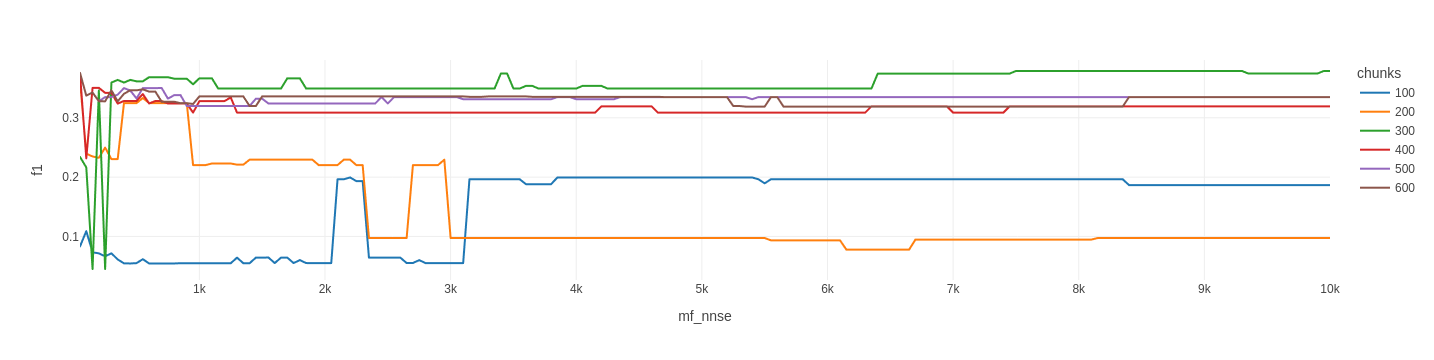

In [24]:
px.line(results, x="mf_nnse", y="f1", color="chunks")